# Projeto Final — Módulo 1
## Manutenção Preditiva de Máquinas

Objetivo: analisar registros operacionais e comparar classificadores para identificar a ocorrência de falhas em máquinas. A variável alvo é `falha_maquina`: **0** representa operação normal e **1** representa falha.

## Fase 1 — Análise Exploratória dos Dados (EDA)

In [28]:

import pandas as pd

dados = pd.read_csv("data/manutencao_preditiva.csv")

dados.head()


,udi,id_produto,tipo,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min,falha_maquina,falha_twf,falha_hdf,falha_pwf,falha_osf,falha_rnf
0,1,M14860,M,298.1,308.6,1551.0,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408.0,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498.0,49.4,5,0,0,0,0,0,0
3,4,L47183,L,NaN,NaN,NaN,NaN,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408.0,40.0,9,0,0,0,0,0,0


In [29]:

print("Dimensões:", dados.shape)
print("\nTipos de dados:")
print(dados.dtypes)
print("\nEstatísticas descritivas:")
print(dados.describe())


Dimensões: (10000, 14)

Tipos de dados:
udi                          int64
id_produto                     str
tipo                           str
temperatura_ar_k           float64
temperatura_processo_k     float64
velocidade_rotacao_rpm     float64
torque_nm                  float64
desgaste_ferramenta_min      int64
falha_maquina                int64
falha_twf                    int64
falha_hdf                    int64
falha_pwf                    int64
falha_osf                    int64
falha_rnf                    int64
dtype: object

Estatísticas descritivas:
               udi  temperatura_ar_k  temperatura_processo_k  \
count  10000.00000       9500.000000             9500.000000   
mean    5000.50000        300.002158              310.000895   
std     2886.89568          2.001689                1.486432   
min        1.00000        295.300000              305.700000   
25%     2500.75000        298.300000              308.800000   
50%     5000.50000        300.100000         

In [30]:

display(dados.describe().T)


,count,mean,std,min,25%,50%,75%,max
udi,10000.0,5000.500000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
temperatura_ar_k,9500.0,300.002158,2.001689,295.3,298.30,300.1,301.50,304.5
temperatura_processo_k,9500.0,310.000895,1.486432,305.7,308.80,310.1,311.10,313.8
velocidade_rotacao_rpm,9500.0,1539.245263,180.273589,1168.0,1423.00,1504.0,1613.00,2886.0
torque_nm,9500.0,39.974168,9.995453,3.8,33.10,40.1,46.70,76.6
desgaste_ferramenta_min,10000.0,107.951000,63.654147,0.0,53.00,108.0,162.00,253.0
falha_maquina,10000.0,0.033900,0.180981,0.0,0.00,0.0,0.00,1.0
falha_twf,10000.0,0.004600,0.067671,0.0,0.00,0.0,0.00,1.0
falha_hdf,10000.0,0.011500,0.106625,0.0,0.00,0.0,0.00,1.0
falha_pwf,10000.0,0.009500,0.097009,0.0,0.00,0.0,0.00,1.0


In [31]:

dados["falha_maquina"].value_counts()


falha_maquina
0    9661
1     339
Name: count, dtype: int64

### Gráficos analíticos

**Gráfico 1 — Frequência da variável alvo**

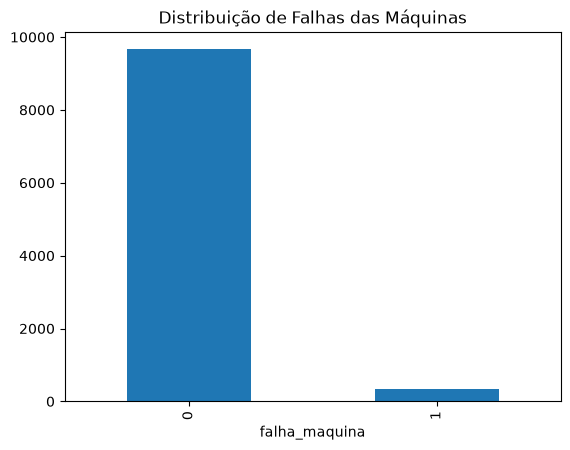

In [32]:

import matplotlib.pyplot as plt

dados["falha_maquina"].value_counts().plot(kind="bar")
plt.title("Distribuição de Falhas das Máquinas")
plt.show()


### Gráfico 2 — Distribuição do torque
O histograma mostra a frequência dos valores de torque registrados.


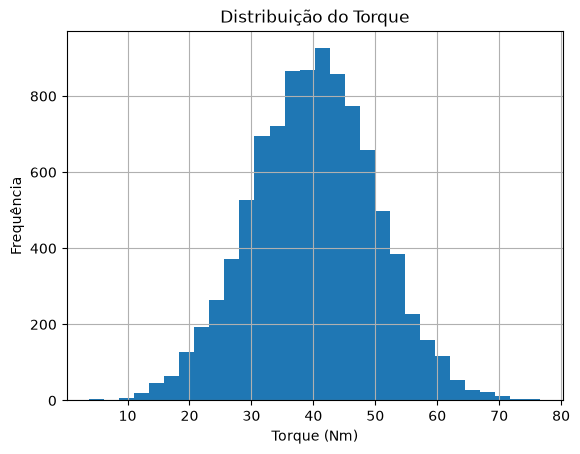

In [33]:

import matplotlib.pyplot as plt
dados["torque_nm"].hist(bins=30)
plt.title("Distribuição do Torque")
plt.xlabel("Torque (Nm)")
plt.ylabel("Frequência")
plt.show()


### Gráfico 3 — Correlação entre variáveis
A matriz de Pearson considera as variáveis numéricas operacionais e a variável alvo; identificadores e indicadores do motivo da falha ficam fora da comparação.


In [34]:
import seaborn as sns

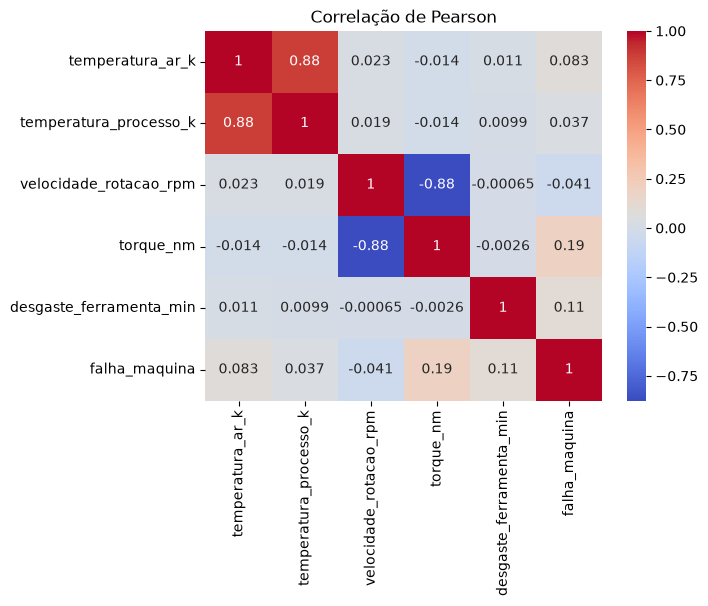

In [35]:

correlacao = dados[[
    "temperatura_ar_k",
    "temperatura_processo_k",
    "velocidade_rotacao_rpm",
    "torque_nm",
    "desgaste_ferramenta_min",
    "falha_maquina"
]].corr(method="pearson")
 
sns.heatmap(correlacao, annot=True, cmap="coolwarm")
plt.title("Correlação de Pearson")
plt.show()


### Observações da Fase 1

A base possui **10.000 registros e 14 colunas**. São **9.661 registros de operação normal (96,61%)** e **339 registros de falha (3,39%)**, indicando forte desbalanceamento entre as classes. Dessa forma, uma acurácia elevada pode ocorrer mesmo com baixa detecção das falhas.

O histograma mostra o torque concentrado próximo de **40 Nm**, com poucos registros nas extremidades. Na matriz de Pearson, a temperatura do ar e a do processo apresentam correlação positiva forte (aproximadamente **0,88**). Já a velocidade de rotação e o torque têm correlação negativa forte (aproximadamente **-0,88**). A correlação linear entre torque e falha é positiva, mas fraca (**0,19**); o desgaste da ferramenta também apresenta correlação positiva fraca com a falha (**0,11**). Correlação não implica causalidade.

Esses resultados indicam a necessidade de tratar dados ausentes, preservar informações operacionais relevantes e lidar com o desbalanceamento apenas no treinamento. O escalonamento também será importante para um classificador baseado em distâncias, como o KNN.


## Fase 2 — Limpeza e Tratamento dos Dados (Data Prep)

São verificadas linhas duplicadas, ausências nas variáveis operacionais e observações extremas (outliers). Os registros atípicos não serão removidos automaticamente, pois podem representar situações relevantes para a ocorrência de falhas.


In [36]:

dados.duplicated().sum()
dados.isna().sum()


udi                          0
id_produto                   0
tipo                         0
temperatura_ar_k           500
temperatura_processo_k     500
velocidade_rotacao_rpm     500
torque_nm                  500
desgaste_ferramenta_min      0
falha_maquina                0
falha_twf                    0
falha_hdf                    0
falha_pwf                    0
falha_osf                    0
falha_rnf                    0
dtype: int64

In [37]:

print("Registros duplicados:", dados.duplicated().sum())


Registros duplicados: 0


### Boxplots — Inspeção dos valores extremos


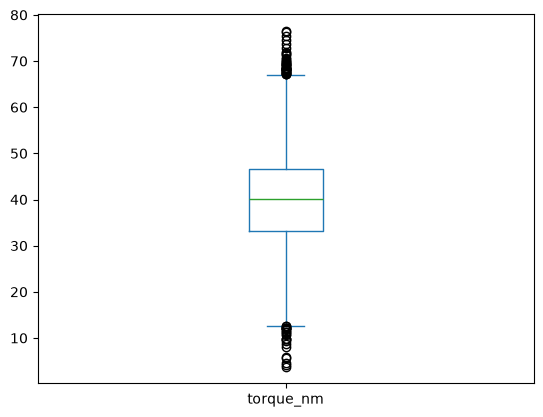

In [38]:

dados["torque_nm"].plot.box()
plt.show()


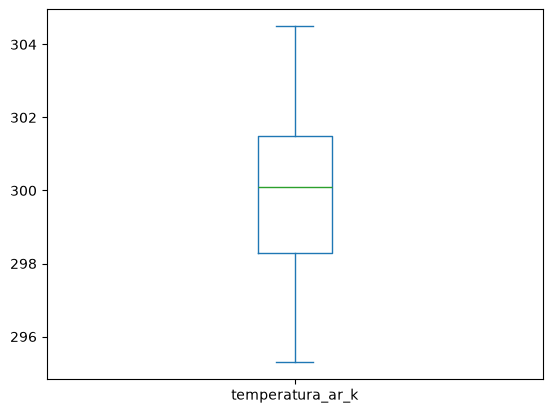

In [39]:
dados["temperatura_ar_k"].plot.box()
plt.show()

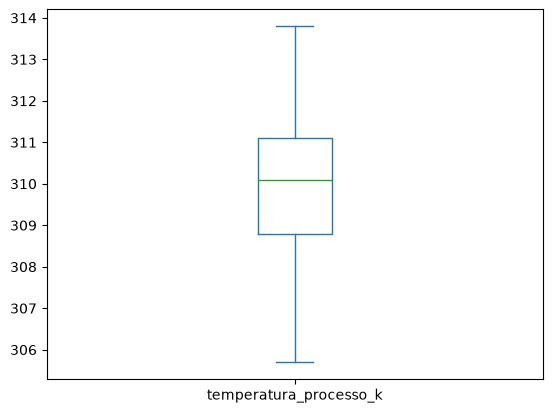

In [40]:
dados["temperatura_processo_k"].plot.box()
plt.show()

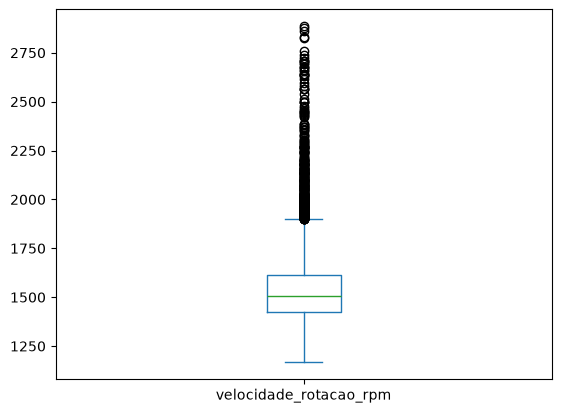

In [41]:
dados["velocidade_rotacao_rpm"].plot.box()
plt.show()

### Observações sobre duplicatas e outliers

A verificação não identificou **linhas duplicadas**, portanto a remoção de duplicatas mantém os **10.000 registros**. Foram identificados **500 valores ausentes (5%) em cada uma** destas quatro colunas: `temperatura_ar_k`, `temperatura_processo_k`, `velocidade_rotacao_rpm` e `torque_nm`.

Os boxplots das temperaturas não mostram pontos extremos pelo critério utilizado. Já a velocidade de rotação apresenta diversos valores elevados fora dos limites usuais do boxplot, e o torque apresenta pontos extremos nas duas extremidades. Por esse motivo, foi escolhida a **média** para as temperaturas e a **mediana** para rotação e torque, por sua maior resistência a valores extremos.


In [42]:
df_limpo = dados.drop_duplicates()

print("Registros após a limpeza:", df_limpo.shape[0])


Registros após a limpeza: 10000


### Separação prévia ao preenchimento dos valores ausentes

Embora a divisão entre treino e teste também faça parte da **Fase 4**, ela precisa ocorrer **antes da imputação** para evitar vazamento de informações. As médias e medianas serão calculadas exclusivamente a partir dos dados de treinamento e depois aplicadas ao teste.

As colunas `udi` e `id_produto` são identificadores. As colunas `falha_twf`, `falha_hdf`, `falha_pwf`, `falha_osf` e `falha_rnf` descrevem causas já conhecidas de falha, por isso não foram usadas como preditoras. A categoria `tipo` foi codificada em variáveis indicadoras.


In [43]:

import pandas as pd
from sklearn.model_selection import train_test_split


# Variáveis explicativas e alvo
X = pd.get_dummies(
    df_limpo[["tipo", "temperatura_ar_k", "temperatura_processo_k", "velocidade_rotacao_rpm", "torque_nm", "desgaste_ferramenta_min"]],
    dtype=int
)
y = df_limpo["falha_maquina"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Treino:", X_train.shape)
print("Teste:", X_test.shape)



Treino: (8000, 8)
Teste: (2000, 8)


### Aplicação da imputação

Os conjuntos foram separados com **80% para treino e 20% para teste**, preservando a proporção de falhas com `stratify=y` e usando `random_state=42` para reprodutibilidade. A etapa seguinte calcula as estatísticas no treino e as reutiliza no teste.


In [44]:

# Calcular as estatísticas somente com os dados de treino
media_ar = X_train["temperatura_ar_k"].mean()
media_processo = X_train["temperatura_processo_k"].mean()
mediana_rotacao = X_train["velocidade_rotacao_rpm"].median()
mediana_torque = X_train["torque_nm"].median()

# Preencher temperaturas com a média
X_train["temperatura_ar_k"] = X_train["temperatura_ar_k"].fillna(media_ar)
X_test["temperatura_ar_k"] = X_test["temperatura_ar_k"].fillna(media_ar)

X_train["temperatura_processo_k"] = X_train["temperatura_processo_k"].fillna(media_processo)
X_test["temperatura_processo_k"] = X_test["temperatura_processo_k"].fillna(media_processo)

# Preencher rotação e torque com a mediana
X_train["velocidade_rotacao_rpm"] = X_train["velocidade_rotacao_rpm"].fillna(mediana_rotacao)
X_test["velocidade_rotacao_rpm"] = X_test["velocidade_rotacao_rpm"].fillna(mediana_rotacao)

X_train["torque_nm"] = X_train["torque_nm"].fillna(mediana_torque)
X_test["torque_nm"] = X_test["torque_nm"].fillna(mediana_torque)

# Conferir o tratamento
print("Nulos no treino:", X_train.isna().sum().sum())
print("Nulos no teste:", X_test.isna().sum().sum())
print("Dimensões do treino:", X_train.shape)
print("Dimensões do teste:", X_test.shape)


Nulos no treino: 0
Nulos no teste: 0
Dimensões do treino: (8000, 8)
Dimensões do teste: (2000, 8)


### Resultado do tratamento

Após a imputação, as quatro variáveis numéricas anteriormente incompletas não possuem valores ausentes em nenhum dos conjuntos. As dimensões permanecem **8.000 × 8** no treinamento e **2.000 × 8** no teste. Nenhuma informação estatística do conjunto de teste foi usada para definir os valores de preenchimento.

## Fase 3 — Feature Engineering

Foi criada a variável `potencia_indicativa` pela multiplicação da velocidade de rotação em RPM pelo torque em Nm, após o preenchimento dos valores ausentes. Essa combinação resume duas condições operacionais em um único atributo. **Não representa diretamente potência em watts**, pois o cálculo físico da potência exigiria converter RPM em velocidade angular (rad/s).


In [45]:

# Fase 3 - Engenharia de Atributos

# Criar indicador operacional no treinamento
X_train["potencia_indicativa"] = (
    X_train["velocidade_rotacao_rpm"] *
    X_train["torque_nm"]
)

# Aplicar o mesmo cálculo no teste
X_test["potencia_indicativa"] = (
    X_test["velocidade_rotacao_rpm"] *
    X_test["torque_nm"]
)

# Validar os resultados
print("Treino:", X_train.shape)
print("Teste:", X_test.shape)

print("Nulos no treino:", X_train.isna().sum().sum())
print("Nulos no teste:", X_test.isna().sum().sum())



Treino: (8000, 9)
Teste: (2000, 9)
Nulos no treino: 0
Nulos no teste: 0


### Resultado da engenharia de atributos

A coluna `potencia_indicativa` foi adicionada aos conjuntos de treino e teste, que passaram a ter **9 atributos** cada, sem valores ausentes. A mesma fórmula foi utilizada nos dois conjuntos.


## Fase 4 — Divisão e Balanceamento dos Dados

A divisão estratificada de 80/20 foi realizada anteriormente, antes da imputação, para evitar vazamento de dados. Nesta seção, o balanceamento é aplicado somente ao conjunto de treinamento.

In [46]:

from imblearn.under_sampling import RandomUnderSampler


In [47]:

print("Distribuição original do treinamento:")
print(y_train.value_counts())


Distribuição original do treinamento:
falha_maquina
0    7729
1     271
Name: count, dtype: int64


In [48]:

# Criar o balanceador
balanceador = RandomUnderSampler(random_state=42)

# Aplicar aos dados de entrada
X_balanceado, y_balanceado = balanceador.fit_resample(
    X_train,
    y_train
)

# Conferir o resultado
print(y_balanceado.value_counts())


falha_maquina
0    271
1    271
Name: count, dtype: int64


### Resultado do balanceamento

No conjunto de treinamento original havia **7.729 operações normais** e **271 falhas**. Com `RandomUnderSampler(random_state=42)`, permaneceram **271 registros por classe**, totalizando **542 observações balanceadas**. Os **2.000 registros de teste** não foram reamostrados.

O undersampling facilita o treinamento com classes equilibradas, mas descarta muitos registros da classe majoritária. Por isso, seus resultados devem ser interpretados com cautela ao avaliar o modelo em uma base com a distribuição original.


In [49]:

from sklearn.preprocessing import StandardScaler


In [50]:

print("KNN treino:", X_balanceado.shape)
print("KNN teste:", X_test.shape)


KNN treino: (542, 9)
KNN teste: (2000, 9)


## Fase 5 — Escalonamento de Variáveis (StandardScaler)

O KNN compara distâncias entre registros; diferenças de escala podem fazer variáveis numericamente grandes dominarem essas distâncias. Por isso, somente as **seis variáveis contínuas** destinadas ao KNN são padronizadas. O `StandardScaler` é ajustado com `fit_transform()` no treinamento balanceado e depois aplicado com `transform()` ao teste.

As três colunas indicadoras da categoria `tipo` não são escalonadas. Para a Árvore de Decisão, permanecem os dados sem padronização: **a árvore utiliza cortes por limiares e não distâncias**, sendo desnecessário alterar a escala dos atributos.


### Aplicação e verificação do escalonamento

In [51]:

X_knn_train = X_balanceado.copy()
X_knn_test = X_test.copy()


In [52]:

from sklearn.preprocessing import StandardScaler

colunas_continuas = ["temperatura_ar_k",
    "temperatura_processo_k",
    "velocidade_rotacao_rpm",
    "torque_nm",
    "desgaste_ferramenta_min",
    "potencia_indicativa"]

scaler = StandardScaler()

X_knn_train[colunas_continuas] = scaler.fit_transform(
    X_knn_train[colunas_continuas]
)

X_knn_test[colunas_continuas] = scaler.transform(
    X_knn_test[colunas_continuas]
)


In [55]:

print(X_knn_train[colunas_continuas].mean().round(3))
print(X_knn_train[colunas_continuas].std().round(3))


temperatura_ar_k           0.0
temperatura_processo_k    -0.0
velocidade_rotacao_rpm     0.0
torque_nm                  0.0
desgaste_ferramenta_min   -0.0
potencia_indicativa        0.0
dtype: float64
temperatura_ar_k           1.001
temperatura_processo_k     1.001
velocidade_rotacao_rpm     1.001
torque_nm                  1.001
desgaste_ferramenta_min    1.001
potencia_indicativa        1.001
dtype: float64


### Verificação da padronização

As médias das seis variáveis contínuas escalonadas no treino ficaram próximas de **0** e os desvios-padrão amostrais em aproximadamente **1,001**. Essa pequena diferença em relação a 1 ocorre porque o `StandardScaler` usa desvio-padrão populacional, enquanto o método `std()` do Pandas utiliza, por padrão, a correção amostral.


## Fase 6 — Ajuste de Parâmetros e Combate ao Overfitting   

In [53]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score


In [54]:

print("KNN treino:", X_knn_train.shape)
print("KNN teste:", X_knn_test.shape)


KNN treino: (542, 9)
KNN teste: (2000, 9)


In [56]:

# KNN com K = 3
knn_3 = KNeighborsClassifier(n_neighbors=3)

# Treinamento
knn_3.fit(X_knn_train, y_balanceado)

# Previsões
previsao_treino = knn_3.predict(X_knn_train)
previsao_teste = knn_3.predict(X_knn_test)

# Cálculo das acurácias
acuracia_treino = accuracy_score(y_balanceado, previsao_treino)
acuracia_teste = accuracy_score(y_test, previsao_teste)

# Resultados
print("KNN - K = 3")
print(f"Acurácia treinamento: {acuracia_treino:.4f}")
print(f"Acurácia teste: {acuracia_teste:.4f}")


KNN - K = 3
Acurácia treinamento: 0.9114
Acurácia teste: 0.8425


In [57]:

# KNN com K = 5
knn_5 = KNeighborsClassifier(n_neighbors=5)

# Treinamento
knn_5.fit(X_knn_train, y_balanceado)

# Previsões
previsao_treino = knn_5.predict(X_knn_train)
previsao_teste = knn_5.predict(X_knn_test)

# Cálculo das acurácias
acuracia_treino = accuracy_score(y_balanceado, previsao_treino)
acuracia_teste = accuracy_score(y_test, previsao_teste)

# Resultados
print("KNN - K = 5")
print(f"Acurácia treinamento: {acuracia_treino:.4f}")
print(f"Acurácia teste: {acuracia_teste:.4f}")

KNN - K = 5
Acurácia treinamento: 0.8911
Acurácia teste: 0.8535


In [58]:
# KNN com K = 7
knn_7 = KNeighborsClassifier(n_neighbors=7)

# Treinamento
knn_7.fit(X_knn_train, y_balanceado)

# Previsões
previsao_treino = knn_7.predict(X_knn_train)
previsao_teste = knn_7.predict(X_knn_test)

# Cálculo das acurácias
acuracia_treino = accuracy_score(y_balanceado, previsao_treino)
acuracia_teste = accuracy_score(y_test, previsao_teste)

# Resultados
print("KNN - K = 7")
print(f"Acurácia treinamento: {acuracia_treino:.4f}")
print(f"Acurácia teste: {acuracia_teste:.4f}")

KNN - K = 7
Acurácia treinamento: 0.8819
Acurácia teste: 0.8480


In [59]:

# Arvore de Decisao - profundidade maxima 3

arvore_3 = DecisionTreeClassifier(max_depth=3, random_state=42)

# Treinamento
arvore_3.fit(X_balanceado, y_balanceado)

# Previsoes
previsao_treino = arvore_3.predict(X_balanceado)
previsao_teste = arvore_3.predict(X_test)

# Calculo das acuracias
acuracia_treino = accuracy_score(y_balanceado, previsao_treino)
acuracia_teste = accuracy_score(y_test, previsao_teste)

# Resultados
print("Arvore de Decisao - Profundidade 3")
print(f"Acuracia treinamento: {acuracia_treino:.4f}")
print(f"Acuracia teste: {acuracia_teste:.4f}")


Arvore de Decisao - Profundidade 3
Acuracia treinamento: 0.8690
Acuracia teste: 0.8885


In [60]:
# Arvore de Decisao - profundidade maxima 5

arvore_5 = DecisionTreeClassifier(max_depth=5, random_state=42)

# Treinamento
arvore_5.fit(X_balanceado, y_balanceado)

# Previsoes
previsao_treino = arvore_5.predict(X_balanceado)
previsao_teste = arvore_5.predict(X_test)

# Calculo das acuracias
acuracia_treino = accuracy_score(y_balanceado, previsao_treino)
acuracia_teste = accuracy_score(y_test, previsao_teste)

# Resultados
print("Arvore de Decisao - Profundidade 5")
print(f"Acuracia treinamento: {acuracia_treino:.4f}")
print(f"Acuracia teste: {acuracia_teste:.4f}")

Arvore de Decisao - Profundidade 5
Acuracia treinamento: 0.9446
Acuracia teste: 0.8875


In [61]:
# Arvore de Decisao - profundidade maxima 7

arvore_7 = DecisionTreeClassifier(max_depth=7, random_state=42)

# Treinamento
arvore_7.fit(X_balanceado, y_balanceado)

# Previsoes
previsao_treino = arvore_7.predict(X_balanceado)
previsao_teste = arvore_7.predict(X_test)

# Calculo das acuracias
acuracia_treino = accuracy_score(y_balanceado, previsao_treino)
acuracia_teste = accuracy_score(y_test, previsao_teste)

# Resultados
print("Arvore de Decisao - Profundidade 7")
print(f"Acuracia treinamento: {acuracia_treino:.4f}")
print(f"Acuracia teste: {acuracia_teste:.4f}")

Arvore de Decisao - Profundidade 7
Acuracia treinamento: 0.9723
Acuracia teste: 0.8880


In [62]:
# Arvore de Decisao - sem limite de profundidade

arvore_sem_limite = DecisionTreeClassifier(max_depth=None, random_state=42)

# Treinamento
arvore_sem_limite.fit(X_balanceado, y_balanceado)

# Previsoes
previsao_treino = arvore_sem_limite.predict(X_balanceado)
previsao_teste = arvore_sem_limite.predict(X_test)

# Calculo das acuracias
acuracia_treino = accuracy_score(y_balanceado, previsao_treino)
acuracia_teste = accuracy_score(y_test, previsao_teste)

# Resultados
print("Arvore de Decisao - Profundidade Sem Limite")
print(f"Acuracia treinamento: {acuracia_treino:.4f}")
print(f"Acuracia teste: {acuracia_teste:.4f}")

Arvore de Decisao - Profundidade Sem Limite
Acuracia treinamento: 1.0000
Acuracia teste: 0.8770


### Observações da Fase 6 — Hiperparâmetros e overfitting

| Modelo | Acurácia no treino | Acurácia no teste |
|:--|--:|--:|
| KNN — K = 3 | 91,14% | 84,25% |
| **KNN — K = 5** | **89,11%** | **85,35%** |
| KNN — K = 7 | 88,19% | 84,80% |
| **Árvore — profundidade 3** | **86,90%** | **88,85%** |
| Árvore — profundidade 5 | 94,46% | 88,75% |
| Árvore — profundidade 7 (teste adicional) | 97,23% | 88,80% |
| Árvore — sem limite de profundidade | 100,00% | 87,70% |

O **KNN com K = 5** obteve a maior acurácia de teste entre os três valores de K. Nas árvores, a acurácia de treino cresce com a profundidade, mas a de teste não acompanha esse crescimento. A árvore sem limite chega a **100% no treino e 87,70% no teste**, diferença de **12,30 pontos percentuais**, um sinal claro de sobreajuste. A árvore com profundidade 3 apresenta a maior acurácia de teste entre as árvores avaliadas e desempenho mais estável na comparação treino/teste.

Uma ressalva: a acurácia de treinamento foi medida sobre dados balanceados, enquanto a de teste usa a distribuição real de classes. Portanto, as duas porcentagens não são perfeitamente comparáveis como prova isolada de overfitting; a complexidade crescente e a queda de teste também fundamentam essa interpretação.


## Fase 7 — Avaliação da Acurácia e Veredito Final

Os melhores resultados de teste de cada família de classificadores, calculados nas células de treinamento acima, foram:

| Melhor configuração | Acurácia final no teste |
|:--|--:|
| **KNN — K = 5** | **85,35%** |
| **Árvore de Decisão — `max_depth=3`** | **88,85%** |

A Árvore de Decisão com profundidade 3 apresentou **3,50 pontos percentuais** de acurácia de teste a mais que o melhor KNN. Assim, **considerando a acurácia solicitada como critério do projeto**, a escolha é a **Árvore de Decisão com profundidade 3**. Além disso, restringir a profundidade reduz a complexidade do modelo e evita o comportamento extremo observado na árvore sem limite.

**Limitação:** a classe de falhas representa apenas **3,39% dos registros**. Um classificador que previsse sempre “sem falha” atingiria aproximadamente **96,61%** de acurácia, mesmo sem detectar uma única avaria. Logo, a escolha acima atende ao critério de comparação pedido, mas **não demonstra, por si só, aptidão para uso industrial**. Uma implantação real exigiria também avaliar a matriz de confusão, o *recall* da classe de falha, a precisão e os custos dos falsos negativos. As métricas deste notebook são relativas à base histórica e ao particionamento utilizado.
